# Lab: K-Nearest Neighbors (KNN), built from scratch

**Goal:** use a patient's details to predict whether the patient has **diabetes**.
KNN is written from scratch (NumPy and Pandas only, no scikit-learn).

**Idea:** KNN is a *lazy learner*. It learns nothing during training and only remembers the data.
When a new patient arrives, it finds the **K most similar** past patients and decides by their **majority**.

**You need:** `patient_data.csv` in the same folder as this notebook.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
FEATURES = ["Age", "BMI", "BloodPressure", "Glucose", "FamilyHistory", "Smoker"]
TARGET = "Outcome"

df = pd.read_csv("patient_data.csv")
print("Shape:", df.shape)
print("Share of diabetes (1): {:.1%}".format(df[TARGET].mean()))
df.head()

Shape: (1000, 7)
Share of diabetes (1): 30.3%


   Age   BMI  BloodPressure  Glucose  FamilyHistory  Smoker  Outcome
0   49  20.7             98       70              0       1        0
1   30  30.3            103       87              0       1        0
2   56  23.8            100       96              0       0        1
3   58  28.2            100       95              0       0        0
4   20  21.2             99       60              0       1        0

## Step 1: The dataset columns

| Column | Meaning |
|---|---|
| `Age`, `BMI`, `BloodPressure`, `Glucose` | number features |
| `FamilyHistory`, `Smoker` | 0 / 1 features |
| `Outcome` | **Target**: 1 = Diabetes, 0 = No diabetes |

In [2]:
df.describe().round(2)

           Age      BMI  BloodPressure  ...  FamilyHistory   Smoker  Outcome
count  1000.00  1000.00        1000.00  ...        1000.00  1000.00  1000.00
mean     44.79    23.24         104.84  ...           0.31     0.25     0.30
std      13.27     3.97          10.04  ...           0.46     0.43     0.46
min      20.00    16.00          70.00  ...           0.00     0.00     0.00
25%      35.00    20.40          98.00  ...           0.00     0.00     0.00
50%      45.00    23.30         105.00  ...           0.00     0.00     0.00
75%      53.00    25.90         111.00  ...           1.00     0.25     1.00
max      80.00    35.80         136.00  ...           1.00     1.00     1.00

[8 rows x 7 columns]

## Step 2: Train / test split and scaling

* **Stratified split (80/20):** both parts keep the same share of diabetic patients.
* **Scaling (z-score):** `z = (x - mean) / std`. KNN works on **distance**. Without scaling, `BloodPressure` (about 100) would overpower `Smoker` (0 or 1).
* The mean and std come from the **train data only**, so the model never sees the test data (this avoids data leakage).

In [3]:
def stratified_train_test_split(X, y, test_size=0.2, seed=SEED):
    # Keeps the same class ratio in both the train set and the test set
    rng = np.random.default_rng(seed)
    train_idx, test_idx = [], []
    for cls in np.unique(y):
        idx = np.where(y == cls)[0]
        rng.shuffle(idx)
        n_test = int(round(len(idx) * test_size))
        test_idx.extend(idx[:n_test])
        train_idx.extend(idx[n_test:])
    train_idx, test_idx = np.array(train_idx), np.array(test_idx)
    rng.shuffle(train_idx)
    rng.shuffle(test_idx)
    return X[train_idx], X[test_idx], y[train_idx], y[test_idx]


class StandardScaler:
    # z = (x - mean) / std   (mean and std are learned from TRAIN data only)
    def fit(self, X):
        self.mean_ = X.mean(axis=0)
        self.std_ = X.std(axis=0)
        self.std_[self.std_ == 0] = 1.0
        return self

    def transform(self, X):
        return (X - self.mean_) / self.std_


X = df[FEATURES].to_numpy(dtype=float)
y = df[TARGET].to_numpy(dtype=int)

X_train, X_test, y_train, y_test = stratified_train_test_split(X, y, test_size=0.2)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Share of diabetic in train: {:.3f} | in test: {:.3f}".format(y_train.mean(), y_test.mean()))

scaler = StandardScaler().fit(X_train)
Xtr, Xte = scaler.transform(X_train), scaler.transform(X_test)
print("\nTrain mean after scaling (about 0):", Xtr.mean(axis=0).round(2))
print("Train std after scaling  (about 1):", Xtr.std(axis=0).round(2))

Train: (800, 6) | Test: (200, 6)
Share of diabetic in train: 0.302 | in test: 0.305

Train mean after scaling (about 0): [ 0. -0. -0. -0. -0. -0.]
Train std after scaling  (about 1): [1. 1. 1. 1. 1. 1.]


## Step 3: The KNN classifier (from scratch)

**`fit()`**: only remembers the training data.

**`predict()`**: for each test point
1. find the **distance** to every training point
   * Euclidean: `d = sqrt( sum( (x_i - t_i)^2 ) )`
   * Manhattan: `d = sum( |x_i - t_i| )`
2. pick the **K smallest distances** (the neighbors)
3. let the neighbors **vote**. The most common class wins.
   * *Weighted* option: closer neighbors get a bigger vote (`weight = 1 / distance`)

In [4]:
class KNNClassifier:
    def __init__(self, k=5, metric="euclidean", weighted=False):
        self.k = k
        self.metric = metric        # "euclidean" or "manhattan"
        self.weighted = weighted    # True: closer neighbors get a bigger vote

    def fit(self, X, y):
        # Lazy learner: just remember the data
        self.X_train = np.asarray(X, dtype=float)
        self.y_train = np.asarray(y, dtype=int)
        return self

    def _distances(self, x):
        # Distance from one test point x to all training points (vectorized)
        diff = self.X_train - x
        if self.metric == "euclidean":
            return np.sqrt(np.sum(diff ** 2, axis=1))
        if self.metric == "manhattan":
            return np.sum(np.abs(diff), axis=1)
        raise ValueError("metric must be 'euclidean' or 'manhattan'")

    def predict_proba_one(self, x):
        dist = self._distances(x)
        nn_idx = np.argsort(dist)[: self.k]          # the K closest neighbors
        nn_labels = self.y_train[nn_idx]
        if self.weighted:
            w = 1.0 / (dist[nn_idx] + 1e-9)           # closer = bigger weight
        else:
            w = np.ones(len(nn_idx))
        classes = np.unique(self.y_train)
        scores = np.array([w[nn_labels == c].sum() for c in classes])
        return classes, scores / scores.sum()

    def predict(self, X):
        preds = []
        for x in np.asarray(X, dtype=float):
            classes, proba = self.predict_proba_one(x)
            preds.append(classes[np.argmax(proba)])
        return np.array(preds)

### A small demo: the neighbors of one test patient

Let us look at the 5 closest neighbors of the first test patient and see how they voted.

In [5]:
demo = KNNClassifier(k=5).fit(Xtr, y_train)
x0 = Xte[0]
dist = demo._distances(x0)
nn = np.argsort(dist)[:5]

print("Test patient #0 true label:", y_test[0])
print("\n5 closest neighbors:")
for rank, i in enumerate(nn, 1):
    print(f"  {rank}. train row {i:>3} | distance = {dist[i]:.3f} | label = {y_train[i]}")
print("\nVotes (class 0, class 1):", np.bincount(y_train[nn], minlength=2),
      "-> prediction =", demo.predict(x0.reshape(1, -1))[0])

Test patient #0 true label: 1

5 closest neighbors:
  1. train row 147 | distance = 0.246 | label = 0
  2. train row 250 | distance = 0.616 | label = 1
  3. train row 252 | distance = 0.674 | label = 0
  4. train row 322 | distance = 0.760 | label = 1
  5. train row 749 | distance = 0.784 | label = 0

Votes (class 0, class 1): [3 2] -> prediction = 0


## Step 4: Metrics (from scratch)

Confusion matrix `[[TN, FP], [FN, TP]]`:

* **Accuracy** = (TP + TN) / total
* **Precision** = TP / (TP + FP) (of the patients we called diabetic, how many really were)
* **Recall** = TP / (TP + FN) (of the really diabetic patients, how many we found)
* **F1** = the harmonic mean of precision and recall

In [6]:
def confusion_matrix(y_true, y_pred):
    # Returns [[TN, FP], [FN, TP]]
    tn = int(np.sum((y_true == 0) & (y_pred == 0)))
    fp = int(np.sum((y_true == 0) & (y_pred == 1)))
    fn = int(np.sum((y_true == 1) & (y_pred == 0)))
    tp = int(np.sum((y_true == 1) & (y_pred == 1)))
    return np.array([[tn, fp], [fn, tp]])


def classification_report(y_true, y_pred):
    (tn, fp), (fn, tp) = confusion_matrix(y_true, y_pred)
    accuracy = (tp + tn) / len(y_true)
    precision = tp / (tp + fp) if (tp + fp) else 0.0
    recall = tp / (tp + fn) if (tp + fn) else 0.0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) else 0.0
    return {"accuracy": accuracy, "precision": precision, "recall": recall, "f1": f1}


def plot_confusion_matrix(cm, title):
    fig, ax = plt.subplots(figsize=(4.5, 4))
    ax.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=14)
    ax.set_xticks([0, 1], ["Pred 0", "Pred 1"])
    ax.set_yticks([0, 1], ["Actual 0", "Actual 1"])
    ax.set_title(title)
    fig.tight_layout()
    plt.show()

## Step 5: Find the best K (5-fold cross-validation)

* If K is **too small** (like 1), the model memorizes noise. This is **overfitting**.
* If K is **too large**, the model becomes too smooth and misses details. This is **underfitting**.
* We use **odd** K values so that votes cannot tie.

Cross-validation uses the **train data only**. The test data is never used to choose K.

5-fold CV accuracy
  K= 1: 0.7575
  K= 3: 0.8038
  K= 5: 0.8113
  K= 7: 0.8075
  K= 9: 0.8287   <-- best
  K=11: 0.8275
  K=13: 0.8187
  K=15: 0.8100
  K=17: 0.8150
  K=19: 0.8275
  K=21: 0.8187
  K=23: 0.8225
  K=25: 0.8188
  K=27: 0.8150
  K=29: 0.8162
  K=31: 0.8138

Best K = 9


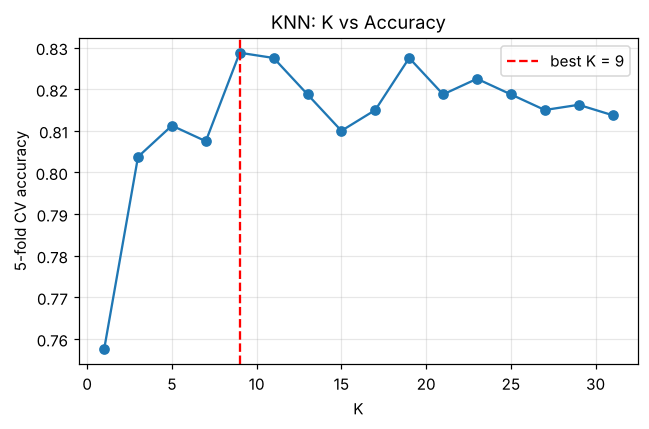

In [7]:
def cross_validate_k(X, y, k_values, folds=5, metric="euclidean", seed=SEED):
    rng = np.random.default_rng(seed)
    idx = rng.permutation(len(X))
    fold_ids = np.array_split(idx, folds)
    results = {}
    for k in k_values:
        accs = []
        for i in range(folds):
            val_idx = fold_ids[i]
            tr_idx = np.concatenate([fold_ids[j] for j in range(folds) if j != i])
            sc = StandardScaler().fit(X[tr_idx])
            model = KNNClassifier(k=k, metric=metric).fit(sc.transform(X[tr_idx]), y[tr_idx])
            pred = model.predict(sc.transform(X[val_idx]))
            accs.append(np.mean(pred == y[val_idx]))
        results[k] = float(np.mean(accs))
    return results


k_values = list(range(1, 32, 2))
cv = cross_validate_k(X_train, y_train, k_values, folds=5)
best_k = max(cv, key=cv.get)

print("5-fold CV accuracy")
for k, a in cv.items():
    print(f"  K={k:>2}: {a:.4f}" + ("   <-- best" if k == best_k else ""))
print("\nBest K =", best_k)

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(list(cv.keys()), list(cv.values()), marker="o")
ax.axvline(best_k, color="red", linestyle="--", label=f"best K = {best_k}")
ax.set_xlabel("K")
ax.set_ylabel("5-fold CV accuracy")
ax.set_title("KNN: K vs Accuracy")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

## Step 6: Final test on the test set

With the best K, we compare three versions: Euclidean, Manhattan and distance-weighted.

In [8]:
configs = [
    ("Euclidean, majority vote", dict(metric="euclidean", weighted=False)),
    ("Manhattan, majority vote", dict(metric="manhattan", weighted=False)),
    ("Euclidean, distance-weighted", dict(metric="euclidean", weighted=True)),
]

print(f"Test-set results (K = {best_k})")
print(f"{'Config':<32}{'Acc':>8}{'Prec':>8}{'Recall':>8}{'F1':>8}")
for name, cfg in configs:
    m = KNNClassifier(k=best_k, **cfg).fit(Xtr, y_train)
    r = classification_report(y_test, m.predict(Xte))
    print(f"{name:<32}{r['accuracy']:>8.3f}{r['precision']:>8.3f}{r['recall']:>8.3f}{r['f1']:>8.3f}")

Test-set results (K = 9)
Config                               Acc    Prec  Recall      F1
Euclidean, majority vote           0.835   0.818   0.590   0.686
Manhattan, majority vote           0.845   0.800   0.656   0.721
Euclidean, distance-weighted       0.830   0.800   0.590   0.679


Confusion matrix (rows = actual, cols = predicted)
                 Pred 0   Pred 1
  Actual 0 (No)     131        8
  Actual 1 (Yes)     25       36
{'accuracy': np.float64(0.835), 'precision': np.float64(0.818), 'recall': np.float64(0.59), 'f1': np.float64(0.686)}


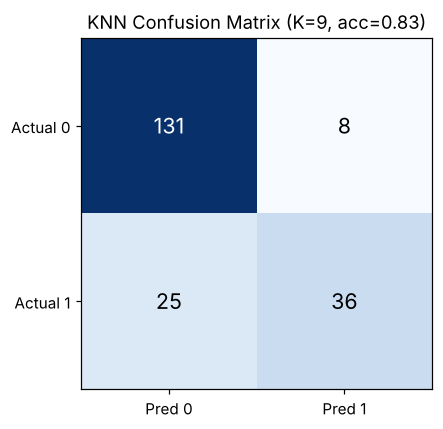

In [9]:
model = KNNClassifier(k=best_k, metric="euclidean").fit(Xtr, y_train)
y_pred = model.predict(Xte)
cm = confusion_matrix(y_test, y_pred)
rep = classification_report(y_test, y_pred)

print("Confusion matrix (rows = actual, cols = predicted)")
print("                 Pred 0   Pred 1")
print(f"  Actual 0 (No)  {cm[0,0]:>6}   {cm[0,1]:>6}")
print(f"  Actual 1 (Yes) {cm[1,0]:>6}   {cm[1,1]:>6}")
print({k: round(v, 3) for k, v in rep.items()})

plot_confusion_matrix(cm, f"KNN Confusion Matrix (K={best_k}, acc={rep['accuracy']:.2f})")

## Step 7: Predict for a new patient

In [10]:
new_patient = np.array([[52, 31.5, 130, 140, 1, 0]], dtype=float)   # Age, BMI, BP, Glucose, Family, Smoker
cls, proba = model.predict_proba_one(scaler.transform(new_patient)[0])
p_diabetes = proba[list(cls).index(1)]

print("New patient: Age=52, BMI=31.5, BP=130, Glucose=140, Family=1, Smoker=0")
print(f"P(Diabetes) = {p_diabetes:.2f}  ->  {'DIABETIC' if p_diabetes >= 0.5 else 'NOT diabetic'}")

New patient: Age=52, BMI=31.5, BP=130, Glucose=140, Family=1, Smoker=0
P(Diabetes) = 1.00  ->  DIABETIC


## Conclusion

* The best K was chosen with cross-validation.
* Accuracy is good, but **recall is low**. The model misses many diabetic patients (false negatives).
  In a medical problem a false negative is costly, so do not trust accuracy alone.
* To improve recall, the decision threshold can be lowered below 0.5.

**Strengths of KNN:** easy to understand, no training step, can learn non-linear boundaries.
**Weaknesses:** slow predictions (distance to every training point), scaling is required, and useless features hurt it.